# End-to-end example: Ce and Gd temperature study

A full pass over a small study: load the files, check how they were recorded, describe the study explicitly, pick emission lines from the NIST Handbook, integrate them, and compare each temperature against 300 °C.

The data folder `data/end_to_end` holds Cerium and Gadolinium LIBS spectra in LiCl-KCl at 1 and 5 wt.%, each measured at 300, 350 and 400 °C:

```
data/end_to_end/
├── Ce/1_wt%/   Ce/5_wt%/
└── Gd/1_wt%/   Gd/5_wt%/
```

Requirements: the package installed in this kernel (`pip install -e .` from the repo root) and the NIST database (`libs-viewer nist build`, see step 5).

> **Just want the results?** `LV.run_study(...)` does all of this in one call, including spotting the mixed-settings file. See [quick_study.ipynb](quick_study.ipynb). This notebook shows what happens inside it.

## 1. Load the data

`LoadLIBSData` reads every `.tdms` file under the folder (`recursive=True` includes the sub-folders) and behaves like a read-only dict keyed by the path relative to that folder.

`overview()` shows how every file was recorded: locations, stored spectra, shots per location, accumulated or single shots, and the settings that matter for a fair comparison.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import libs_viewer.libs as LV
from libs_viewer.libs.plotting import plot_spectrum
from libs_viewer.nist import query

# The repository root, found from wherever the notebook is started (repo root or examples/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())

data = LV.LoadLIBSData(ROOT / 'data' / 'end_to_end', recursive=True)
data.overview()

C:\Users\Jack\Desktop\Academic GitHub Repos\LIBS_Viewer\src\libs_viewer\libs\loading.py:374: SettingsWarning: Gd_Sample5_300_3.5delay.tdms: settings differ between stored spectra: ['Gate Delay (usec)', 'Accumulate', 'Energy', 'Number Of Shots', 'Rep Rate', 'Warmup Energy', '# Of Warmup Shots', 'Setpoint (2)'] (see varying_params())
  self.data[f.relative_to(root).as_posix()] = LIBSFile.from_tdms(f)


,locations,spectra,shots per location,stored as,energy (mJ),gate delay (us),mixed settings
file,,,,,,,
Ce/1_wt%/Ce1 350 new location.tdms,2,20,10,single shots,80.0,1.0,
Ce/1_wt%/Ce1400.tdms,2,20,10,single shots,80.0,1.0,
Ce/1_wt%/Ce1_300C.tdms,2,20,10,single shots,80.0,1.0,
Ce/5_wt%/Ce_Sample2_Temp_300C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/5_wt%/Ce_Sample2_Temp_350C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/5_wt%/Ce_Sample2_Temp_400C.tdms,2,10,5,single shots,80.0,3.5,
Gd/1_wt%/Gd_Sample1_300.tdms,2,2,5,accumulated,80.0,2.5,
Gd/1_wt%/Gd_Sample1_350.tdms,1,1,5,accumulated,80.0,2.5,
Gd/1_wt%/Gd_Sample1_400.tdms,1,1,5,accumulated,80.0,2.5,


## 2. Check the acquisition settings

The files are not all recorded the same way. Some are *accumulated* (each stored spectrum is the sum of 5 shots at one location), others are *single shots* (Ce 1 wt%: 2 locations × 10 shots, each shot stored on its own). That is fine for averages, because every spectrum is put on a counts-per-shot scale first, but it matters for the scatter (step 8).

The loader also warned that one file has **settings that differ between its stored spectra**. `acquisitions` shows every stored spectrum with its location, shot and settings:

In [2]:
odd = data['Gd/5_wt%/Gd_Sample5_300_3.5delay.tdms']
odd.acquisitions[['location', 'shot', 'shots_summed', 'Accumulate', 'Gate Delay (usec)', 'Energy']]

,location,shot,shots_summed,Accumulate,Gate Delay (usec),Energy
spectrum,,,,,,
Grid Location # 1-1,1,1,5.0,1.0,3.5,80.0
Grid Location # 2-1,2,1,1.0,0.0,1.0,10.0
Grid Location # 2-2,2,2,1.0,0.0,1.0,10.0
Grid Location # 2-3,2,3,1.0,0.0,1.0,10.0
Grid Location # 2-4,2,4,1.0,0.0,1.0,10.0
Grid Location # 2-5,2,5,1.0,0.0,1.0,10.0
Grid Location # 2-6,2,6,1.0,0.0,1.0,10.0
Grid Location # 2-7,2,7,1.0,0.0,1.0,10.0
Grid Location # 2-8,2,8,1.0,0.0,1.0,10.0


Location 1 (`Grid Location # 1-1`) is one spectrum of 5 accumulated shots at 3.5 µs and 80 mJ, like the rest of the Gd 5 wt% series. Location 2 (`2-1 … 2-10`) is 10 single shots at 1.0 µs and 10 mJ, a different experiment, so it must be left out. The manifest below does that.

Some differences are expected and harmless: each sample keeps its own gate delay (Ce 1 wt% 1.0 µs, Gd 1 wt% 2.5 µs, the 5 wt% samples 3.5 µs), and samples are only ever compared with themselves at a different temperature.

## 3. Describe the study (the manifest)

The file names don't follow one pattern (`Ce1400.tdms`, `Ce1 350 new location.tdms`, `Gd_Sample1_300.tdms`), so instead of guessing, every file is mapped explicitly to its element, sample and temperature. `use_columns` picks the stored spectra to keep (`None` = all).

The same table, saved as a CSV, can be passed straight to `LV.study_plan` / `LV.run_study` as `manifest=` (`use_columns` as names separated by `;`). For folders whose names do follow a pattern, `pattern='{element}/{sample}/*{temperature}*'` builds it for you.

In [3]:
manifest = pd.DataFrame([
    # file                                     element  sample      temperature  use_columns
    ('Ce/1_wt%/Ce1_300C.tdms',                 'Ce',    'Ce 1 wt%', 300,         None),
    ('Ce/1_wt%/Ce1 350 new location.tdms',     'Ce',    'Ce 1 wt%', 350,         None),
    ('Ce/1_wt%/Ce1400.tdms',                   'Ce',    'Ce 1 wt%', 400,         None),
    ('Ce/5_wt%/Ce_Sample2_Temp_300C.tdms',     'Ce',    'Ce 5 wt%', 300,         None),
    ('Ce/5_wt%/Ce_Sample2_Temp_350C.tdms',     'Ce',    'Ce 5 wt%', 350,         None),
    ('Ce/5_wt%/Ce_Sample2_Temp_400C.tdms',     'Ce',    'Ce 5 wt%', 400,         None),
    ('Gd/1_wt%/Gd_Sample1_300.tdms',           'Gd',    'Gd 1 wt%', 300,         None),
    ('Gd/1_wt%/Gd_Sample1_350.tdms',           'Gd',    'Gd 1 wt%', 350,         None),
    ('Gd/1_wt%/Gd_Sample1_400.tdms',           'Gd',    'Gd 1 wt%', 400,         None),
    ('Gd/5_wt%/Gd_Sample5_300_3.5delay.tdms',  'Gd',    'Gd 5 wt%', 300,         ['Grid Location # 1-1']),
    ('Gd/5_wt%/Gd_Sample5_350_3.5delay.tdms',  'Gd',    'Gd 5 wt%', 350,         None),
    ('Gd/5_wt%/Gd_Sample5_400_3.5delay.tdms',  'Gd',    'Gd 5 wt%', 400,         None),
], columns=['file', 'element', 'sample', 'temperature', 'use_columns'])

# Every loaded file must be in the manifest and vice versa
assert set(manifest.file) == set(data.keys()), set(manifest.file) ^ set(data.keys())
SAMPLES = list(manifest['sample'].unique())
REF_T = 300   # reference temperature for the ratios
manifest

,file,element,sample,temperature,use_columns
0,Ce/1_wt%/Ce1_300C.tdms,Ce,Ce 1 wt%,300,None
1,Ce/1_wt%/Ce1 350 new location.tdms,Ce,Ce 1 wt%,350,None
2,Ce/1_wt%/Ce1400.tdms,Ce,Ce 1 wt%,400,None
3,Ce/5_wt%/Ce_Sample2_Temp_300C.tdms,Ce,Ce 5 wt%,300,None
4,Ce/5_wt%/Ce_Sample2_Temp_350C.tdms,Ce,Ce 5 wt%,350,None
5,Ce/5_wt%/Ce_Sample2_Temp_400C.tdms,Ce,Ce 5 wt%,400,None
6,Gd/1_wt%/Gd_Sample1_300.tdms,Gd,Gd 1 wt%,300,None
7,Gd/1_wt%/Gd_Sample1_350.tdms,Gd,Gd 1 wt%,350,None
8,Gd/1_wt%/Gd_Sample1_400.tdms,Gd,Gd 1 wt%,400,None
9,Gd/5_wt%/Gd_Sample5_300_3.5delay.tdms,Gd,Gd 5 wt%,300,[Grid Location # 1-1]


`subset` keeps only the listed spectra, so from here on every step sees just what is used. Within each sample the key settings should then match across temperatures:

In [4]:
files = {r.file: data[r.file] if r.use_columns is None else data[r.file].subset(columns=r.use_columns)
         for r in manifest.itertuples()}

rows = {}
for r in manifest.itertuples():
    f = files[r.file]
    key = f.acquisitions[['Gate Delay (usec)', 'Energy']]
    assert (key.nunique() == 1).all(), f'{r.file}: kept spectra still differ'
    rows[(r.sample, r.temperature)] = {'gate delay (us)': key.iloc[0, 0], 'energy (mJ)': key.iloc[0, 1],
                                       'recorded as': f.describe()}
pd.DataFrame.from_dict(rows, orient='index')

gate delay (us)  energy (mJ)  \
Ce 1 wt% 300              1.0         80.0   
         350              1.0         80.0   
         400              1.0         80.0   
Ce 5 wt% 300              3.5         80.0   
         350              3.5         80.0   
         400              3.5         80.0   
Gd 1 wt% 300              2.5         80.0   
         350              2.5         80.0   
         400              2.5         80.0   
Gd 5 wt% 300              3.5         80.0   
         350              3.5         80.0   
         400              3.5         80.0   

                                        recorded as  
Ce 1 wt% 300  2 locations x 10 shots (single shots)  
         350  2 locations x 10 shots (single shots)  
         400  2 locations x 10 shots (single shots)  
Ce 5 wt% 300     1 location x 5 shots (accumulated)  
         350     1 location x 5 shots (accumulated)  
         400   2 locations x 5 shots (single shots)  
Gd 1 wt% 300    2 locations x 5 shots (accumulated)  
         350     1 location x 5 shots (accumulated)  
         400     1 location x 5 shots (accumulated)  
Gd 5 wt% 300     1 location x 5 shots (accumulated)  
         350   2 locations x 5 shots (single shots)  
         400   2 locations x 5 shots (single shots)

## 4. Per-shot spectra and saturated pixels

For every sample and temperature, `per_shot_spectrum` divides all counts by all shots, so every shot weighs the same whether it was stored on its own or accumulated.

`saturated_mask` flags pixels where the detector clipped (~65 000 counts per shot) in *any* stored spectrum at *any* temperature of a sample. The same pixels are then dropped at every temperature for the *Total (excl. sat.)* row, so the totals stay comparable.

In [5]:
wl = data[0].wavelengths           # all files share one wavelength axis
assert all(np.array_equal(f.wavelengths, wl) for f in files.values())

spectra, masks = {}, {}            # spectra[sample][temperature] -> per-shot spectrum
for sample, g in manifest.groupby('sample', sort=False):
    spectra[sample] = {t: LV.per_shot_spectrum(files[k]) for k, t in zip(g.file, g.temperature)}
    masks[sample] = LV.saturated_mask([files[k] for k in g.file])

pd.Series({s: int(m.sum()) for s, m in masks.items()}, name='saturated pixels')

Ce 1 wt%     51
Ce 5 wt%    110
Gd 1 wt%    159
Gd 5 wt%     46
Name: saturated pixels, dtype: int64

## 5. Pick lines from the NIST Handbook

The line lookups need the local NIST database in the per-user data folder (`libs-viewer paths` shows where). Build it once with `libs-viewer nist build`.

In [6]:
info = query.database_info()
info['path'], info['elements']

('C:\\Users\\Jack\\AppData\\Local\\libs_viewer\\nist_handbook.sqlite', 99)

For each element, `select_lines` takes the strongest NIST lines and keeps those that show a clean peak in the 300 °C spectrum of its samples. It rejects lines that sit near a saturated pixel or within 0.15 nm of a strong line of the *other* element (Ce and Gd lines interleave in this region).

Two things specific to this data:

- **Calibration offset.** Peaks sit about 0.05 nm below the NIST wavelengths (Ce II 418.66 nm shows up at 418.60 nm). That is inside the default `peak_tol` of 0.1 nm, so nothing needs shifting.
- **Weak lines at 1 wt%.** Ce 1 wt% was recorded with a 1.0 µs gate, so its continuum is high and its lines are small on top of it: the prominence of Ce II 418.66 is ~300 counts on a ~900 count continuum. The default threshold (prominence ≥ 2 × the spectrum's median) finds no Ce line there at all, so `min_prominence=0.25` is used.

In [7]:
ELEMENTS = {'Ce': 'Gd', 'Gd': 'Ce'}             # element -> the element that may interfere
line_tables = {}
for el, other in ELEMENTS.items():
    samples = manifest.loc[manifest.element == el, 'sample'].unique()
    line_tables[el] = LV.select_lines(
        el, wl,
        y_refs={s: spectra[s][REF_T] for s in samples},
        n=4, interferents=[other],
        exclude=np.logical_or.reduce([masks[s] for s in samples]),
        min_prominence=0.25)

show = ['label', 'intensity', 'status', 'detected_in']
line_tables['Ce'][show].head(20)

,label,intensity,status,detected_in
0,Ce I 569.92,1000,no peak in spectrum,[]
1,Ce II 418.66,1000,picked,"[Ce 1 wt%, Ce 5 wt%]"
2,Ce II 395.25,900,interference: Gd I 395.34,[]
3,Ce II 399.92,800,picked,[Ce 5 wt%]
4,Ce II 413.38,800,interference: Gd I 413.42,[]
5,Ce I 516.15,800,blended (neighbour line too close) / no peak i...,[]
6,Ce II 401.24,800,picked,[Ce 5 wt%]
7,Ce II 394.27,800,near saturated region,[]
8,Ce I 515.97,800,blended (neighbour line too close) / no peak i...,[]
9,Ce I 569.70,800,interference: Gd I 569.62,[]


In [8]:
line_tables['Gd'][show].head(12)

,label,intensity,status,detected_in
0,Gd II 376.84,1000,not needed,[Gd 1 wt%]
1,Gd I 422.59,1000,no peak in spectrum,[]
2,Gd II 342.25,800,picked,"[Gd 1 wt%, Gd 5 wt%]"
3,Gd II 364.62,700,picked,"[Gd 1 wt%, Gd 5 wt%]"
4,Gd II 358.50,600,picked,"[Gd 1 wt%, Gd 5 wt%]"
5,Gd II 335.05,600,picked,"[Gd 1 wt%, Gd 5 wt%]"
6,Gd I 378.31,600,not needed,"[Gd 1 wt%, Gd 5 wt%]"
7,Gd II 385.10,600,blended (neighbour line too close),[]
8,Gd II 379.64,600,not needed,"[Gd 1 wt%, Gd 5 wt%]"
9,Gd I 407.87,600,not needed,"[Gd 1 wt%, Gd 5 wt%]"


Lines found in more samples are preferred, but a line is only integrated in the samples where it was actually detected:

In [9]:
LINES = {}                                      # LINES[sample] = {label: wavelength_nm}
for sample, el in manifest.groupby('sample', sort=False).element.first().items():
    picked = line_tables[el].query("status == 'picked'")
    LINES[sample] = {r.label: r.wavelength_nm for r in picked.itertuples() if sample in r.detected_in}
LINES

{'Ce 1 wt%': {'Ce II 418.66': 418.65959999999995, 'Ce II 413.76': 413.7649},
 'Ce 5 wt%': {'Ce II 418.66': 418.65959999999995,
  'Ce II 399.92': 399.9237,
  'Ce II 401.24': 401.2387,
  'Ce II 413.76': 413.7649},
 'Gd 1 wt%': {'Gd II 342.25': 342.24699999999996,
  'Gd II 364.62': 364.619,
  'Gd II 358.50': 358.496,
  'Gd II 335.05': 335.04699999999997},
 'Gd 5 wt%': {'Gd II 342.25': 342.24699999999996,
  'Gd II 364.62': 364.619,
  'Gd II 358.50': 358.496,
  'Gd II 335.05': 335.04699999999997}}

## 6. Look at the spectra

`plot_spectrum` returns a matplotlib `Figure` (it never calls `plt.show()`), so it displays when it is the last expression of a cell and can be saved with `fig.savefig(...)`. The picked lines are marked as reference lines.

For Ce 1 wt% the plot warns that it finds no peak at the two Ce lines. Its own peak finder uses the stricter default threshold, and the zoom shows why: at 300 °C both lines are only just above the noise.

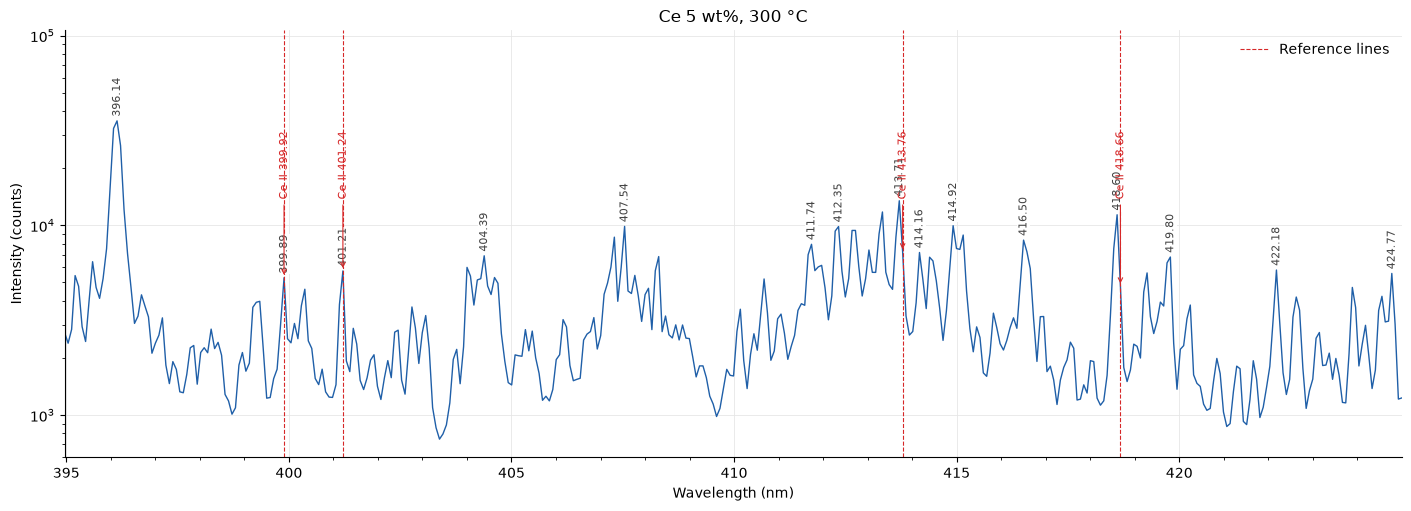

In [10]:
plot_spectrum(wl, spectra['Ce 5 wt%'][REF_T], title=f'Ce 5 wt%, {REF_T} °C',
              ref_lines=LINES['Ce 5 wt%'], wl_range=(395, 425))

C:\Users\Jack\AppData\Local\Temp\ipykernel_30708\1962188855.py:1: UserWarning: no peak within 0.2 nm of 418.65959999999995 nm (nearest peak: 396.77 nm)
  plot_spectrum(wl, spectra['Ce 1 wt%'][REF_T], title=f'Ce 1 wt%, {REF_T} °C',
C:\Users\Jack\AppData\Local\Temp\ipykernel_30708\1962188855.py:1: UserWarning: no peak within 0.2 nm of 413.7649 nm (nearest peak: 396.77 nm)
  plot_spectrum(wl, spectra['Ce 1 wt%'][REF_T], title=f'Ce 1 wt%, {REF_T} °C',


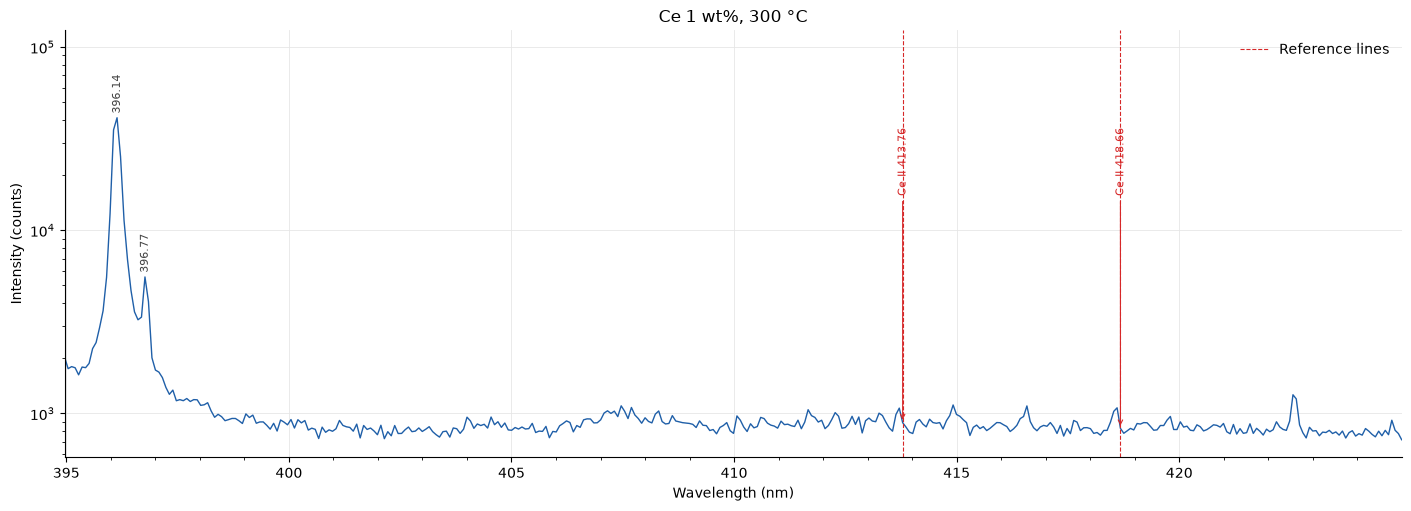

In [11]:
plot_spectrum(wl, spectra['Ce 1 wt%'][REF_T], title=f'Ce 1 wt%, {REF_T} °C',
              ref_lines=LINES['Ce 1 wt%'], wl_range=(395, 425))

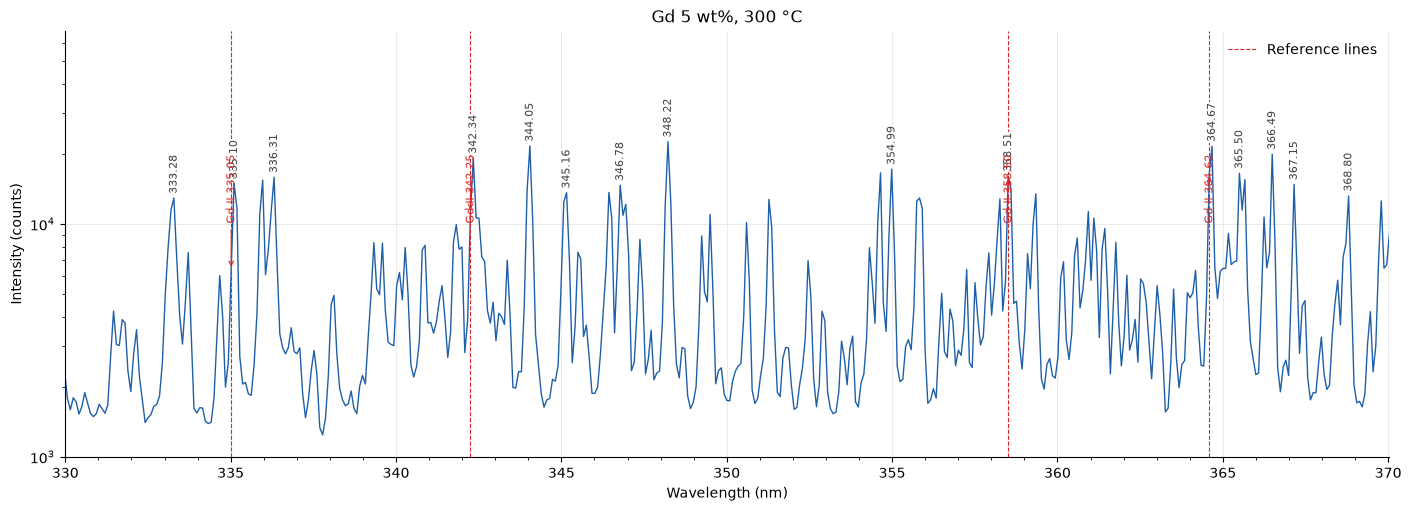

In [12]:
plot_spectrum(wl, spectra['Gd 5 wt%'][REF_T], title=f'Gd 5 wt%, {REF_T} °C',
              ref_lines=LINES['Gd 5 wt%'], wl_range=(330, 370))

## 7. Line areas and ratios

`analyze_sample` finds each line's integration window once, on the 300 °C spectrum, and uses the same pixels at every temperature. The line area is measured above a straight local baseline. The totals are the integral of the continuum-corrected (SNIP) spectrum, with and without the saturated pixels.

`ratio_tables` then gives, relative to 300 °C:

- `R_direct` = A(T) / A(300) for every row, so the *Total* rows are R_total, the change in overall emitted light.
- `R_rel` = [A_line(T) / A_total(T)] / [A_line(300) / A_total(300)], the change in the line *relative to the whole spectrum*, which cancels plasma-to-plasma changes in overall brightness.

In [13]:
areas, ratios = {}, {}
for sample in SAMPLES:
    areas[sample] = LV.analyze_sample(wl, spectra[sample], LINES[sample],
                                      exclude=masks[sample], ref=REF_T)
    ratios[sample] = LV.ratio_tables(areas[sample], ref=REF_T)

pd.concat(areas, names=['sample', 'row']).round(1)

Temperature (C)                    300        350       400
sample   row                                               
Ce 1 wt% Ce II 418.66             49.8       41.7      96.5
         Ce II 413.76             48.1       47.8      93.0
         Total                263795.2   255833.7  326238.0
         Total (excl. sat.)   217962.9   176685.3  258726.4
Ce 5 wt% Ce II 418.66           1675.2     2116.7     991.0
         Ce II 399.92            390.8      510.5     202.1
         Ce II 401.24            549.9      689.6     316.5
         Ce II 413.76           1378.0     1741.2     773.6
         Total               1007921.2  1140970.6  969168.9
         Total (excl. sat.)   666356.1   807232.6  635239.9
Gd 1 wt% Gd II 342.25           2555.5      114.8      58.7
         Gd II 364.62           1872.9       85.1      47.6
         Gd II 358.50           1529.1       70.1      29.0
         Gd II 335.05           1872.9       78.2      41.5
         Total               1499162.9   562830.6  543983.2
         Total (excl. sat.)   965322.6   246898.7  214207.4
Gd 5 wt% Gd II 342.25           2873.8     1767.1     339.1
         Gd II 364.62           2904.1     1953.0     324.6
         Gd II 358.50           1893.2     1221.5     220.8
         Gd II 335.05           2439.8     1531.4     258.0
         Total               1362233.2  1255102.9  268587.8
         Total (excl. sat.)  1194614.5  1117433.8  199886.6

In [14]:
pd.concat({s: r['R_rel'] for s, r in ratios.items()}, names=['sample', 'row']).round(3)

Temperature (C)              300    350    400
sample   row                                  
Ce 1 wt% Ce II 418.66        1.0  0.864  1.567
         Ce II 413.76        1.0  1.026  1.564
         Total               1.0  0.970  1.237
         Total (excl. sat.)  1.0  0.811  1.187
Ce 5 wt% Ce II 418.66        1.0  1.116  0.615
         Ce II 399.92        1.0  1.154  0.538
         Ce II 401.24        1.0  1.108  0.598
         Ce II 413.76        1.0  1.116  0.584
         Total               1.0  1.132  0.962
         Total (excl. sat.)  1.0  1.211  0.953
Gd 1 wt% Gd II 342.25        1.0  0.120  0.063
         Gd II 364.62        1.0  0.121  0.070
         Gd II 358.50        1.0  0.122  0.052
         Gd II 335.05        1.0  0.111  0.061
         Total               1.0  0.375  0.363
         Total (excl. sat.)  1.0  0.256  0.222
Gd 5 wt% Gd II 342.25        1.0  0.667  0.599
         Gd II 364.62        1.0  0.730  0.567
         Gd II 358.50        1.0  0.700  0.592
         Gd II 335.05        1.0  0.681  0.536
         Total               1.0  0.921  0.197
         Total (excl. sat.)  1.0  0.935  0.167

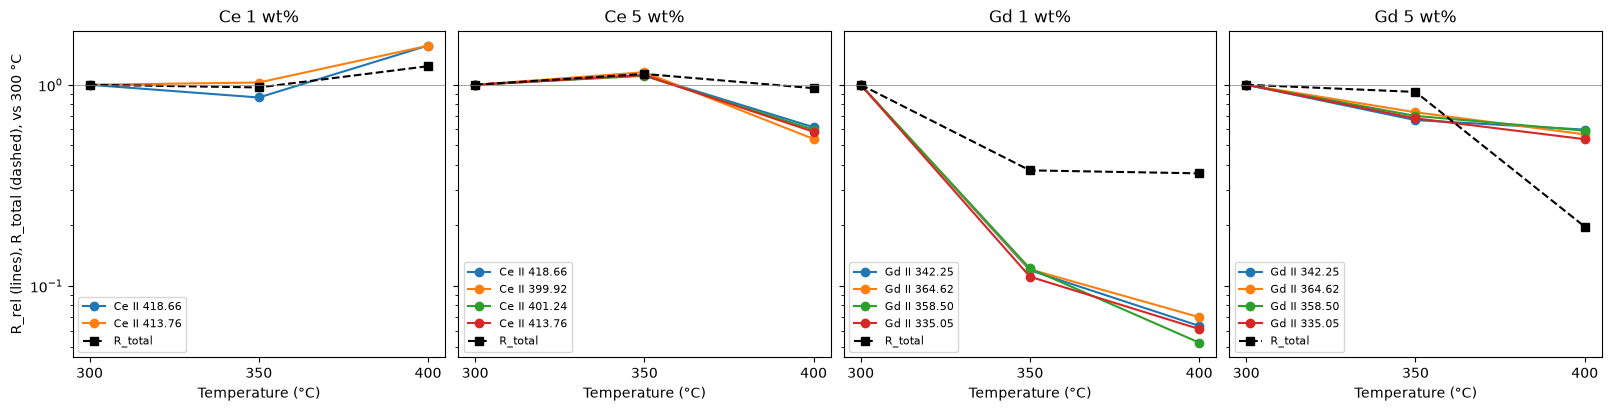

In [15]:
fig, axes = plt.subplots(1, len(SAMPLES), figsize=(16, 4), sharey=True, layout='constrained')
for ax, sample in zip(axes, SAMPLES):
    r = ratios[sample]
    r['R_rel'].drop(index=[LV.TOTAL, LV.TOTAL_EXCL]).T.plot(ax=ax, marker='o')
    r['R_direct'].loc[LV.TOTAL].plot(ax=ax, color='k', ls='--', marker='s', label='R_total')
    ax.axhline(1, color='grey', lw=0.5)
    ax.set_title(sample)
    ax.set_xlabel('Temperature (°C)')
    ax.set_xticks(sorted(spectra[sample]))
    ax.legend(fontsize=8)
axes[0].set_ylabel(f'R_rel (lines), R_total (dashed), vs {REF_T} °C')
axes[0].set_yscale('log');

## 8. Scatter: locations and shots

The ratios above use the mean over all kept shots. How far do single measurements spread around that mean? There are two different questions, and the files answer them differently:

- **Location to location**: `LV.location_spectra(f)` gives the mean per-shot spectrum of every location. Their spread shows how uniform the sample is. It needs 2+ locations.
- **Shot to shot**: `LV.per_shot_columns(f)` gives every stored spectrum per shot. In single-shot files, the spread within one location is the shot-to-shot noise. Accumulated files have no single shots left to compare.

`areas_table` measures any set of spectra with the same windows as above. The spread is given as a coefficient of variation, CV = standard deviation ÷ mean (%):

In [16]:
def cv(table):
    return 100 * table.std(axis=1) / table.mean(axis=1)

rows = {}
for r in manifest.itertuples():
    f, lines = files[r.file], LINES[r.sample]
    windows = LV.line_windows(wl, spectra[r.sample][REF_T], lines)
    row = {'recorded as': f.describe()}

    locs = LV.location_spectra(f)
    if locs.shape[1] > 1:
        c = cv(LV.areas_table(wl, locs, lines, windows, exclude=masks[r.sample]))
        row['location CV, lines (%)'] = c[list(lines)].mean()
        row['location CV, Total (%)'] = c[LV.TOTAL]

    single = f.acquisitions.query('shots_summed == 1')
    if len(single) > 1:
        a = LV.areas_table(wl, LV.per_shot_columns(f)[single.index], lines, windows, exclude=masks[r.sample])
        c = pd.concat({loc: cv(a[g.index]) for loc, g in single.groupby('location') if len(g) > 1},
                      axis=1).mean(axis=1)                    # mean over locations
        row['shot CV, lines (%)'] = c[list(lines)].mean()
        row['shot CV, Total (%)'] = c[LV.TOTAL]
    rows[(r.sample, r.temperature)] = row

pd.DataFrame.from_dict(rows, orient='index').round(1)

recorded as  location CV, lines (%)  \
Ce 1 wt% 300  2 locations x 10 shots (single shots)                    54.5   
         350  2 locations x 10 shots (single shots)                   105.3   
         400  2 locations x 10 shots (single shots)                   108.6   
Ce 5 wt% 300     1 location x 5 shots (accumulated)                     NaN   
         350     1 location x 5 shots (accumulated)                     NaN   
         400   2 locations x 5 shots (single shots)                    79.3   
Gd 1 wt% 300    2 locations x 5 shots (accumulated)                   121.0   
         350     1 location x 5 shots (accumulated)                     NaN   
         400     1 location x 5 shots (accumulated)                     NaN   
Gd 5 wt% 300     1 location x 5 shots (accumulated)                     NaN   
         350   2 locations x 5 shots (single shots)                    60.7   
         400   2 locations x 5 shots (single shots)                    89.3   

              location CV, Total (%)  shot CV, lines (%)  shot CV, Total (%)  
Ce 1 wt% 300                    65.6                77.9                25.1  
         350                    52.2               181.1                40.9  
         400                    17.5                86.7                17.1  
Ce 5 wt% 300                     NaN                 NaN                 NaN  
         350                     NaN                 NaN                 NaN  
         400                    56.3                92.8                52.6  
Gd 1 wt% 300                    69.5                 NaN                 NaN  
         350                     NaN                 NaN                 NaN  
         400                     NaN                 NaN                 NaN  
Gd 5 wt% 300                     NaN                 NaN                 NaN  
         350                    75.6                15.7                 6.5  
         400                    31.9                86.7                31.3

This is the same table `run_study` returns as `result.scatter` (there, files with neither kind of scatter are left out).

**Reading the results**

- **Single measurements scatter a lot.** Single shots at one location spread by 15 to 180 % on the lines (6 to 53 % on the total). The two locations of a file differ by 55 to 120 % on the lines. Every file has at most 2 locations, so each location CV comes from just two numbers and is itself rough. Files recorded at one location (Ce 5 wt% at 300/350 °C, Gd 1 wt% at 350/400 °C, Gd 5 wt% at 300 °C after dropping location 2) give no location estimate at all.
- **Ce 1 wt%**: the lines are barely above the noise, so its ratios (0.86 to 1.57) cannot be told apart from 1.
- **Ce 5 wt%, Gd 1 wt%, Gd 5 wt%**: all lines of an element move together. That fits a real change, but some of it is plasma brightness that every line shares. And within each of these samples the temperatures were recorded differently (1 vs 2 locations, accumulated vs single shots), so a change between temperatures is partly a change of spot. Weigh it against the location scatter above before drawing conclusions.
- **Gd 1 wt%** drops by about 10× from 300 to 350 °C, and its total light drops too. The 300 °C file has two locations and the others one, and its two locations already differ by ~120 % on the lines, so check those spectra first.

## Next steps

- Run the whole study in one call: [quick_study.ipynb](quick_study.ipynb).
- `result.save(...)` writes the tables together with the settings that produced them (`settings.json`).
- Compare baseline methods: `plotting.plot_baseline(wl, y, method='airpls')`, or `method='airpls'` in `analyze_sample` (roadmap phase 4 benchmarks this properly).
- More on locations, shots and `accumulate()`: [loading_data.ipynb](loading_data.ipynb).